# Full Pipeline Simulation: LR55 coarse classifier + QPSK-like blind Rs/CFO CAPNetLite

This notebook trains one LR55 coarse classifier and one CAPNetLite QPSK-like classifier for `SPLIT_MODE = "2022train20"`. All 2018 negative-SNR samples are explicitly excluded from LR training/testing, QPSK-like NN training/testing, and final pipeline evaluation.

1. Train a vector55 LogisticRegression coarse classifier on compact PT vectors to classify all signals into `BPSK`, `MSK`, `DQPSK`, `8PSK`, or `QPSK-like`.
2. Train the QPSK-like CAPNetLite on the precomputed blind-Rs/CFO QPSK-like CC matrices, using the same architecture and hyperparameters as the selected LR9+CAPNetLite reference, while retaining LR55 for coarse classification.
3. Simulate the full pipeline without regenerating CC matrices for every signal:
   - LR predicts a non-QPSK-like class: final prediction is that LR class.
   - LR predicts `QPSK-like` and the true signal is QPSK-like: use the CAPNetLite CC-matrix prediction.
   - LR predicts `QPSK-like` but the true signal is not QPSK-like: no precomputed CC matrix exists, so the final prediction is forced to `QPSK`.
   - True QPSK-like signals predicted as non-QPSK-like by LR do not use CC matrix, matching the simulated pipeline route.
   - If a true QPSK-like sample has no CC matrix after filtering, it is counted as `missing_cc_forced_qpsk`; this should be rare and is not used to represent 2018 negative-SNR samples because those are removed upstream.

The LR55 artifact and CAPNetLite checkpoint are saved under `fully_online_pipeline_models` with the exact names consumed by the fully-online inference notebook.


In [1]:
from pathlib import Path
import sys
import os

# Restrict this notebook to physical CUDA GPU 3 before importing PyTorch.
os.environ["CUDA_VISIBLE_DEVICES"] = "3"


def _find_helper_project_dir(start=Path.cwd()):
    start = Path(start).resolve()
    search_roots = [start, *start.parents]
    for root in search_roots:
        if (root / "helper_function" / "__init__.py").exists():
            return root
    for root in search_roots[:3]:
        matches = list(root.glob("**/boi_shift_fft3_cfpattern_spl/helper_function/__init__.py"))
        if matches:
            return matches[0].parent.parent
    raise FileNotFoundError("Could not find helper_function from the current Jupyter working directory.")


PROJECT_DIR = _find_helper_project_dir()
BASE_DIR = PROJECT_DIR
MODEL_DIR = BASE_DIR / "fully_online_pipeline_models"
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import math, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score

# =========================
# CAPNetLite reproducibility and training config
# (identical to Classfier-CAPNetLite-QPSKlike-11x15-2022train20.ipynb)
# =========================
SPLIT_MODE = "2022train20"
C1 = 32
C2 = 64
WEIGHT_DECAY = 3e-4
LR = 1e-3
BATCH_SIZE = 250
EPOCHS = 200
PATIENCE = 45
PLATEAU_PATIENCE = 8

# Do not fix any RNG seed: each fresh run uses new random states.
torch.use_deterministic_algorithms(False)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

if not torch.cuda.is_available() or torch.cuda.device_count() != 1:
    raise RuntimeError("Physical CUDA GPU 3 is required; expected exactly one visible CUDA device.")
DEVICE = torch.device("cuda:0")
print("CUDA_VISIBLE_DEVICES:", os.environ["CUDA_VISIBLE_DEVICES"])
print("Visible CUDA device:", torch.cuda.get_device_name(0))
print("DEVICE:", DEVICE)


# =========================
# Paths and split mode
# =========================
PT_ROOT = Path("qpsklike_cc_matrix_11x24_blind_rs_cfo_pt_dataset")
PREFIX = {
    "2018": "2018_qpsklike_cc_11x24_blindrs_cfo_batch_",
    "2022": "2022_qpsklike_cc_11x24_blindrs_cfo_batch_",
}
N_BATCHES = 28

# Choose one:
#   "2018train20": train/val/test on 2018 batches, external test on all 2022 batches
#   "2022train20": train/val/test on 2022 batches, external test on all 2018 batches
TRAIN_BATCH_COUNT = 20
VAL_BATCH_COUNT = 4
TEST_BATCH_COUNT = 4
DROP_2018_NEGATIVE_SNR = True

CLASS_NAMES = ["QPSK", "16QAM", "64QAM", "256QAM"]
LABEL_MAP = {"qpsk": 0, "16qam": 1, "64qam": 2, "256qam": 3}
N_CLASSES = len(CLASS_NAMES)


def list_pt_files(year: str):
    return [PT_ROOT / f"{PREFIX[year]}{i:02d}.pt" for i in range(1, N_BATCHES + 1)]

pt_files = {"2018": list_pt_files("2018"), "2022": list_pt_files("2022")}
for year, files in pt_files.items():
    missing = [str(p) for p in files if not p.exists()]
    print(f"missing_{year}:", len(missing))
    if missing:
        print("first missing:", missing[0])


def make_splits(split_mode: str):
    if split_mode == "2018train20":
        train_year, ext_year = "2018", "2022"
    elif split_mode == "2022train20":
        train_year, ext_year = "2022", "2018"
    else:
        raise ValueError("SPLIT_MODE must be '2018train20' or '2022train20'")

    total_needed = TRAIN_BATCH_COUNT + VAL_BATCH_COUNT + TEST_BATCH_COUNT
    if total_needed > N_BATCHES:
        raise ValueError(
            f"Non-overlapping split needs {total_needed} batches, but only {N_BATCHES} exist. "
            "For 8 test batches, reduce VAL_BATCH_COUNT or TRAIN_BATCH_COUNT."
        )

    train_all = pt_files[train_year]
    train_files = train_all[:TRAIN_BATCH_COUNT]
    val_files = train_all[TRAIN_BATCH_COUNT:TRAIN_BATCH_COUNT + VAL_BATCH_COUNT]
    test_files = train_all[TRAIN_BATCH_COUNT + VAL_BATCH_COUNT:total_needed]
    ext_files = pt_files[ext_year][:]
    return train_year, ext_year, train_files, val_files, test_files, ext_files

TRAIN_SET_NAME, EXT_SET_NAME, train_files, val_files, test_files, ext_files = make_splits(SPLIT_MODE)

print("SPLIT_MODE:", SPLIT_MODE)
print("TRAIN on:", TRAIN_SET_NAME)
print("External test on:", EXT_SET_NAME)
print(f"{TRAIN_SET_NAME} train:", [p.name for p in train_files])
print(f"{TRAIN_SET_NAME} val  :", [p.name for p in val_files])
print(f"{TRAIN_SET_NAME} test :", [p.name for p in test_files])
print(f"{EXT_SET_NAME} external test:", [p.name for p in ext_files])


CUDA_VISIBLE_DEVICES: 3
Visible CUDA device: NVIDIA GeForce RTX 3090
DEVICE: cuda:0
missing_2018: 0
missing_2022: 0
SPLIT_MODE: 2022train20
TRAIN on: 2022
External test on: 2018
2022 train: ['2022_qpsklike_cc_11x24_blindrs_cfo_batch_01.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_02.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_03.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_04.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_05.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_06.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_07.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_08.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_09.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_10.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_11.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_12.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_13.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_14.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_15.pt', '2022_qpsklike_cc_11x24_blindrs_cfo_batch_16.pt', '2022_qps

In [2]:
# =========================
# Stage 1: vector55 LogisticRegression coarse classifier
# =========================
import pandas as pd
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

COMPACT_PT_ROOT = PROJECT_DIR
LR_VECTOR_KEY = "lr55"
LR_LABEL5_ORDER = ["BPSK", "MSK", "DQPSK", "8PSK", "QPSK-like"]
FULL8_LABEL_ORDER = ["BPSK", "MSK", "DQPSK", "8PSK", "QPSK", "16QAM", "64QAM", "256QAM"]
QPSKLIKE_SIGNAL_TYPES = {"qpsk", "16qam", "64qam", "256qam"}


def label5_from_signal_type(signal_type):
    sig = str(signal_type).strip().lower()
    if sig == "bpsk":
        return "BPSK"
    if sig == "msk":
        return "MSK"
    if sig == "dqpsk":
        return "DQPSK"
    if sig == "8psk":
        return "8PSK"
    if sig in QPSKLIKE_SIGNAL_TYPES:
        return "QPSK-like"
    raise ValueError(f"Unsupported signal_type={signal_type!r}")


def label8_from_signal_type(signal_type):
    sig = str(signal_type).strip().lower()
    mapping = {
        "bpsk": "BPSK",
        "msk": "MSK",
        "dqpsk": "DQPSK",
        "8psk": "8PSK",
        "qpsk": "QPSK",
        "16qam": "16QAM",
        "64qam": "64QAM",
        "256qam": "256QAM",
    }
    if sig not in mapping:
        raise ValueError(f"Unsupported signal_type={signal_type!r}")
    return mapping[sig]


def list_compact_vector_files(year):
    files = sorted((COMPACT_PT_ROOT / str(year)).glob(f"{year}_batch_*_boi_shift_fft3_compact_vectors.pt"))
    if len(files) != N_BATCHES:
        print(f"Warning: expected {N_BATCHES} compact vector files for {year}, found {len(files)}")
    return files


def load_lr55_vectors(years=("2018", "2022")):
    meta_parts = []
    x_parts = []
    feature_names = None
    t0 = time.time()

    for year in years:
        files = list_compact_vector_files(str(year))
        if not files:
            raise FileNotFoundError(f"No compact vector PT files found under {COMPACT_PT_ROOT / str(year)}")

        for file_idx, path in enumerate(files, start=1):
            pack = torch.load(path, map_location="cpu", weights_only=False)
            samples = pack["samples"]
            names = list(pack["vector_feature_names"][LR_VECTOR_KEY])
            if feature_names is None:
                feature_names = names
            elif feature_names != names:
                raise ValueError(f"{LR_VECTOR_KEY} feature-name mismatch in {path}")

            rows = []
            vectors = []
            for sample in samples:
                meta = sample["meta"]
                truth = sample["truth"]
                signal_type = str(meta["signal_type"]).strip().lower()
                batch_id = int(meta.get("batch_id", pack.get("batch_id", -1)))
                signal_index = int(meta.get("signal_index", meta.get("global_index", -1)))
                rows.append({
                    "year": str(year),
                    "pt_name": path.name,
                    "batch_id": batch_id,
                    "signal_index": signal_index,
                    "signal_type": signal_type,
                    "label5": label5_from_signal_type(signal_type),
                    "label8": label8_from_signal_type(signal_type),
                    "snr": float(truth.get("inband_snr_db_label", truth.get("snr_truth_db", np.nan))),
                    "cc_key": (str(year), batch_id, signal_index),
                })
                vectors.append(np.asarray(sample["vectors"][LR_VECTOR_KEY], dtype=np.float32))

            meta_parts.append(pd.DataFrame(rows))
            x_parts.append(np.vstack(vectors).astype(np.float32, copy=False))
            print(
                f"LR55 load {year} {file_idx:02d}/{len(files):02d} {path.name}: "
                f"rows={len(samples)} errors={pack.get('num_errors', len(pack.get('errors', [])))} "
                f"elapsed={time.time() - t0:.1f}s",
                flush=True,
            )
            del pack, samples

    meta_df = pd.concat(meta_parts, ignore_index=True)
    X = np.vstack(x_parts).astype(np.float32, copy=False)

    if DROP_2018_NEGATIVE_SNR:
        keep = ~((meta_df["year"] == "2018") & (meta_df["snr"] < 0))
        dropped = int((~keep).sum())
        if dropped:
            print(f"LR55 drop 2018 negative-SNR rows: {dropped}")
        meta_df = meta_df.loc[keep].reset_index(drop=True)
        X = X[keep.to_numpy()]

    X = np.where(np.isfinite(X), X, np.nan)
    print("LR55 rows after SNR filter:", len(meta_df), "X:", X.shape, "features:", len(feature_names))
    print("LR55 label5 counts:")
    print(meta_df["label5"].value_counts().reindex(LR_LABEL5_ORDER))
    return meta_df, X, feature_names


lr_meta_df, X_lr55, lr55_feature_names = load_lr55_vectors()
y_lr5 = lr_meta_df["label5"].astype(str).to_numpy()


def make_lr_masks(split_mode):
    if split_mode == "2018train20":
        train_year, ext_year = "2018", "2022"
    elif split_mode == "2022train20":
        train_year, ext_year = "2022", "2018"
    else:
        raise ValueError(split_mode)

    train_mask = (lr_meta_df["year"] == train_year) & (lr_meta_df["batch_id"] <= TRAIN_BATCH_COUNT)
    val_mask = (
        (lr_meta_df["year"] == train_year)
        & (lr_meta_df["batch_id"] > TRAIN_BATCH_COUNT)
        & (lr_meta_df["batch_id"] <= TRAIN_BATCH_COUNT + VAL_BATCH_COUNT)
    )
    test_mask = (
        (lr_meta_df["year"] == train_year)
        & (lr_meta_df["batch_id"] > TRAIN_BATCH_COUNT + VAL_BATCH_COUNT)
        & (lr_meta_df["batch_id"] <= TRAIN_BATCH_COUNT + VAL_BATCH_COUNT + TEST_BATCH_COUNT)
    )
    ext_mask = (lr_meta_df["year"] == ext_year)
    return train_mask.to_numpy(), val_mask.to_numpy(), test_mask.to_numpy(), ext_mask.to_numpy()


lr_train_mask, lr_val_mask, lr_test_mask, lr_ext_mask = make_lr_masks(SPLIT_MODE)

lr55_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        n_jobs=-1,
        class_weight="balanced",
        C=3,
        random_state=None,
    ),
)

print("Training LR55 coarse classifier...")
t0 = time.time()
lr55_model.fit(X_lr55[lr_train_mask], y_lr5[lr_train_mask])
print(f"LR55 trained in {time.time() - t0:.1f}s")

MODEL_DIR = PROJECT_DIR / "fully_online_pipeline_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
LR_MODEL_PATH = MODEL_DIR / f"lr55_{SPLIT_MODE}.joblib"
joblib.dump({
    "model": lr55_model,
    "split_mode": SPLIT_MODE,
    "vector_key": LR_VECTOR_KEY,
    "feature_names": list(lr55_feature_names),
    "class_names": list(LR_LABEL5_ORDER),
    "drop_2018_negative_snr": bool(DROP_2018_NEGATIVE_SNR),
}, LR_MODEL_PATH)
print("Saved LR55 model to:", LR_MODEL_PATH)

for name, mask in [
    ("train", lr_train_mask),
    ("val", lr_val_mask),
    ("same-domain test", lr_test_mask),
    ("external", lr_ext_mask),
]:
    pred = lr55_model.predict(X_lr55[mask])
    acc = accuracy_score(y_lr5[mask], pred)
    cm = pd.DataFrame(
        confusion_matrix(y_lr5[mask], pred, labels=LR_LABEL5_ORDER),
        index=LR_LABEL5_ORDER,
        columns=LR_LABEL5_ORDER,
    )
    print(f"\nLR55 {name}: n={int(mask.sum())} acc={acc*100:.4f}% errors={int((pred != y_lr5[mask]).sum())}")
    display(cm)


LR55 load 2018 01/28 2018_batch_01_boi_shift_fft3_compact_vectors.pt: rows=3992 errors=8 elapsed=12.2s
LR55 load 2018 02/28 2018_batch_02_boi_shift_fft3_compact_vectors.pt: rows=3984 errors=16 elapsed=23.8s
LR55 load 2018 03/28 2018_batch_03_boi_shift_fft3_compact_vectors.pt: rows=3984 errors=16 elapsed=35.0s
LR55 load 2018 04/28 2018_batch_04_boi_shift_fft3_compact_vectors.pt: rows=3984 errors=16 elapsed=45.4s
LR55 load 2018 05/28 2018_batch_05_boi_shift_fft3_compact_vectors.pt: rows=3992 errors=8 elapsed=55.7s
LR55 load 2018 06/28 2018_batch_06_boi_shift_fft3_compact_vectors.pt: rows=3984 errors=16 elapsed=66.8s
LR55 load 2018 07/28 2018_batch_07_boi_shift_fft3_compact_vectors.pt: rows=3984 errors=16 elapsed=77.5s
LR55 load 2018 08/28 2018_batch_08_boi_shift_fft3_compact_vectors.pt: rows=3984 errors=16 elapsed=87.7s
LR55 load 2018 09/28 2018_batch_09_boi_shift_fft3_compact_vectors.pt: rows=3992 errors=8 elapsed=97.9s
LR55 load 2018 10/28 2018_batch_10_boi_shift_fft3_compact_vectors.p

,BPSK,MSK,DQPSK,8PSK,QPSK-like
BPSK,10000,0,0,0,0
MSK,0,10000,0,0,0
DQPSK,0,0,10000,0,0
8PSK,0,0,0,10000,0
QPSK-like,0,0,0,2,39998



LR55 val: n=16000 acc=99.9938% errors=1


,BPSK,MSK,DQPSK,8PSK,QPSK-like
BPSK,2000,0,0,0,0
MSK,0,2000,0,0,0
DQPSK,0,0,2000,0,0
8PSK,0,0,0,2000,0
QPSK-like,0,0,0,1,7999



LR55 same-domain test: n=16000 acc=99.9938% errors=1


,BPSK,MSK,DQPSK,8PSK,QPSK-like
BPSK,2000,0,0,0,0
MSK,0,2000,0,0,0
DQPSK,0,0,2000,0,0
8PSK,0,0,0,2000,0
QPSK-like,0,0,0,1,7999



LR55 external: n=111632 acc=99.8755% errors=139


,BPSK,MSK,DQPSK,8PSK,QPSK-like
BPSK,13954,0,0,0,0
MSK,0,13954,0,0,0
DQPSK,0,0,13953,1,0
8PSK,0,0,1,13949,4
QPSK-like,0,0,25,108,55683


In [3]:
# =========================
# Dataset
# =========================
class QPSKLikeCCDataset(torch.utils.data.Dataset):
    """
    Loads QPSK-like CC matrix .pt files generated from blind Rs/CFO estimates.

    Input feature:
        estimate_abs: [N, 11, 24]

    Processing:
        1) use estimate_abs
        2) cut 11x24 -> 11x15 using X[:, :, :15], same as the old classifier
        3) divide by boi_inband_signal power
        4) final NN input shape is [N, 1, 11, 15]

    No RMS normalization.
    No global mean/std normalization.
    """

    def __init__(self, pt_files, label_map=LABEL_MAP):
        self.pt_files = list(pt_files)
        self.label_map = dict(label_map)
        self.X_list = []
        self.y_list = []
        self.source_file_list = []
        self._load_all()

        self.X = torch.cat(self.X_list, dim=0)
        self.y = torch.cat(self.y_list, dim=0)
        del self.X_list, self.y_list

        if self.X.ndim == 3:
            self.X = self.X.unsqueeze(1)
        elif self.X.ndim != 4:
            raise ValueError(f"Unexpected X dim: {self.X.shape}")

        if self.y.ndim == 2:
            self.y = self.y.squeeze(1)
        self.y = self.y.long()

        self.N, self.C, self.H, self.W = self.X.shape

    def _load_all(self):
        for p in self.pt_files:
            pack = torch.load(p, map_location="cpu", weights_only=False)

            X_all = pack["estimate_abs"].float()
            if X_all.ndim != 3 or tuple(X_all.shape[1:]) != (11, 24):
                raise ValueError(f"{p.name}: expected estimate_abs [N,11,24], got {tuple(X_all.shape)}")

            status = pack.get("status", torch.ones(X_all.shape[0], dtype=torch.bool)).bool()
            signal_type = [str(s).strip().lower() for s in list(pack["signal_type"])]
            label_ok = torch.tensor([s in self.label_map for s in signal_type], dtype=torch.bool)

            power_all = pack["boi_inband_signal"].float()
            power_ok = torch.isfinite(power_all) & (power_all > 0)

            snr_ok = torch.ones(X_all.shape[0], dtype=torch.bool)
            if DROP_2018_NEGATIVE_SNR and p.name.startswith("2018_") and "snr" in pack:
                snr_all = pack["snr"].float()
                snr_ok = torch.isfinite(snr_all) & (snr_all >= 0)

            X_11x15_all = X_all[:, :, :15]
            X_ok = torch.isfinite(X_11x15_all.reshape(X_11x15_all.shape[0], -1)).all(dim=1)

            valid = status & label_ok & power_ok & snr_ok & X_ok
            valid_idx = torch.where(valid)[0]

            X = X_11x15_all[valid]
            power = power_all[valid]

            # The only normalization: BOI in-band power scaling, matching the old notebook.
            X = X / power.view(-1, 1, 1)

            scaled_ok = torch.isfinite(X.reshape(X.shape[0], -1)).all(dim=1)
            X = X[scaled_ok]
            valid_idx = valid_idx[scaled_ok]

            signal_type_valid = [signal_type[i] for i in valid_idx.tolist()]
            y = torch.tensor([self.label_map[s] for s in signal_type_valid], dtype=torch.long)

            self.X_list.append(X)
            self.y_list.append(y)
            self.source_file_list.extend([p.name] * int(X.shape[0]))

            label_counts = {name: int((y == idx).sum()) for idx, name in enumerate(CLASS_NAMES)}
            print(
                f"Loaded {p.name}: X={tuple(X.shape)}, "
                f"valid={X.shape[0]}/{len(signal_type)}, "
                f"bad_status={int((~status).sum())}, "
                f"bad_label={int((~label_ok).sum())}, "
                f"bad_power={int((~power_ok).sum())}, "
                f"bad_snr={int((~snr_ok).sum())}, "
                f"bad_X={int((~X_ok).sum())}, "
                f"power-scale=boi_inband_signal, "
                f"label_counts={label_counts}, "
                f"X min/max=({float(X.min()):.4e}, {float(X.max()):.4e})"
            )

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# =========================
# Build datasets
# =========================
ds_train = QPSKLikeCCDataset(train_files)
ds_val   = QPSKLikeCCDataset(val_files)
ds_test  = QPSKLikeCCDataset(test_files)
ds_ext   = QPSKLikeCCDataset(ext_files)

print("Train raw shape:", ds_train.X.shape, ds_train.y.shape)
print("Val raw shape  :", ds_val.X.shape, ds_val.y.shape)
print("Test raw shape :", ds_test.X.shape, ds_test.y.shape)
print("Ext raw shape  :", ds_ext.X.shape, ds_ext.y.shape)

X0, y0 = ds_train[0]
print("One sample:", X0.shape, int(y0), CLASS_NAMES[int(y0)], "min/max", float(X0.min()), float(X0.max()))


Loaded 2022_qpsklike_cc_11x24_blindrs_cfo_batch_01.pt: X=(2000, 11, 15), valid=2000/2000, bad_status=0, bad_label=0, bad_power=0, bad_snr=0, bad_X=0, power-scale=boi_inband_signal, label_counts={'QPSK': 500, '16QAM': 500, '64QAM': 500, '256QAM': 500}, X min/max=(0.0000e+00, 4.6449e+00)
Loaded 2022_qpsklike_cc_11x24_blindrs_cfo_batch_02.pt: X=(2000, 11, 15), valid=2000/2000, bad_status=0, bad_label=0, bad_power=0, bad_snr=0, bad_X=0, power-scale=boi_inband_signal, label_counts={'QPSK': 500, '16QAM': 500, '64QAM': 500, '256QAM': 500}, X min/max=(0.0000e+00, 5.5712e+00)
Loaded 2022_qpsklike_cc_11x24_blindrs_cfo_batch_03.pt: X=(2000, 11, 15), valid=2000/2000, bad_status=0, bad_label=0, bad_power=0, bad_snr=0, bad_X=0, power-scale=boi_inband_signal, label_counts={'QPSK': 500, '16QAM': 500, '64QAM': 500, '256QAM': 500}, X min/max=(0.0000e+00, 3.3528e+00)
Loaded 2022_qpsklike_cc_11x24_blindrs_cfo_batch_04.pt: X=(2000, 11, 15), valid=2000/2000, bad_status=0, bad_label=0, bad_power=0, bad_snr=0

## Train

In [4]:
# ---------------------------------------------------------------------------
# CAPNetLite: a small FPGA-friendly ResNet-style CNN.
#
# Design choices for ZCU104 PL friendliness:
#   - a single shared trunk + one small FC head
#   - plain 3x3 convs with static padding=1
#   - ReLU activation
#   - BatchNorm folds into the preceding conv at inference
# ---------------------------------------------------------------------------

class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(ch)
        self.conv2 = nn.Conv2d(ch, ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(ch)

    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        out = out + identity
        return F.relu(out, inplace=True)


class CAPNetLite(nn.Module):
    def __init__(self, n_classes=4, c1=32, c2=64):
        super().__init__()
        self.stem = nn.Conv2d(1, c1, kernel_size=3, stride=1, padding=1, bias=False)
        self.stem_bn = nn.BatchNorm2d(c1)
        self.block1 = ResBlock(c1)
        self.down = nn.Conv2d(c1, c2, kernel_size=3, stride=(1, 2), padding=1, bias=False)
        self.down_bn = nn.BatchNorm2d(c2)
        self.block2 = ResBlock(c2)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(c2, n_classes)

    def forward(self, x):
        x = F.relu(self.stem_bn(self.stem(x)), inplace=True)
        x = self.block1(x)
        x = F.relu(self.down_bn(self.down(x)), inplace=True)
        x = self.block2(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
ext_loader = DataLoader(ds_ext, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

model = CAPNetLite(n_classes=N_CLASSES, c1=C1, c2=C2).to(DEVICE)
n_params = count_params(model)
print(f"CAPNetLite params: {n_params:,d}")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=PLATEAU_PATIENCE, min_lr=1e-5)


@torch.no_grad()
def eval_one(loader):
    model.eval()
    ys, ps, losses = [], [], []
    for X, y in loader:
        X = X.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        logits = model(X)
        loss = criterion(logits, y)
        losses.append(loss.item())
        ys.append(y.cpu())
        ps.append(logits.argmax(dim=1).cpu())
    y_true = torch.cat(ys).numpy()
    y_pred = torch.cat(ps).numpy()
    return float(np.mean(losses)), float(accuracy_score(y_true, y_pred)), y_true, y_pred


def train_one_epoch():
    model.train()
    losses = []
    correct = 0
    total = 0
    for X, y in train_loader:
        X = X.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.numel()
    return float(np.mean(losses)), float(correct / total)


SAVE_DIR = MODEL_DIR
SAVE_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = SAVE_DIR / f"capnet_lite_c{C1}_{C2}_{SPLIT_MODE}.pt"
print("Best model will be saved to:", BEST_MODEL_PATH)

best_val_acc = -1.0
best_epoch = -1
no_improve = 0
best_state = None

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch()
    va_loss, va_acc, _, _ = eval_one(val_loader)

    improved = va_acc > best_val_acc + 1e-4
    if improved:
        best_val_acc = va_acc
        best_epoch = epoch
        no_improve = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, BEST_MODEL_PATH)
    else:
        no_improve += 1

    if epoch % 10 == 0 or epoch == 1 or no_improve >= PATIENCE:
        lr_now = optimizer.param_groups[0]["lr"]
        print(f"Epoch {epoch:03d} | lr {lr_now:.2e} | train {tr_loss:.4f}/{tr_acc*100:5.2f}% | val {va_loss:.4f}/{va_acc*100:5.2f}% | best {best_val_acc*100:5.2f}%@{best_epoch}")
    scheduler.step(va_acc)

    if no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

print("Training time (min):", (time.time() - t0) / 60.0)
if best_state is None:
    raise RuntimeError("No best validation state was captured during training.")


CAPNetLite params: 111,716
Best model will be saved to: /home/ruilin/SPL_Surreal/SPL_code/spl_sourcecode/fully_online_pipeline_models/capnet_lite_c32_64_2022train20.pt
Epoch 001 | lr 1.00e-03 | train 0.6329/70.49% | val 0.4490/78.66% | best 78.66%@1


Epoch 010 | lr 1.00e-03 | train 0.3497/82.34% | val 0.3850/79.22% | best 79.22%@10
Epoch 020 | lr 1.00e-03 | train 0.3436/82.43% | val 0.5773/72.45% | best 83.33%@18
Epoch 030 | lr 1.00e-03 | train 0.3386/82.89% | val 0.3520/82.09% | best 83.40%@22
Epoch 040 | lr 5.00e-04 | train 0.3217/83.71% | val 0.4063/78.99% | best 83.89%@39
Epoch 050 | lr 5.00e-04 | train 0.3234/83.73% | val 0.3153/84.55% | best 84.55%@50
Epoch 060 | lr 5.00e-04 | train 0.3136/84.42% | val 0.4399/77.54% | best 84.95%@51
Epoch 070 | lr 2.50e-04 | train 0.3026/84.80% | val 0.4090/79.77% | best 85.01%@69
Epoch 080 | lr 2.50e-04 | train 0.2991/85.18% | val 0.3436/82.59% | best 85.25%@78
Epoch 090 | lr 1.25e-04 | train 0.2827/86.01% | val 0.3790/80.55% | best 85.80%@88
Epoch 100 | lr 6.25e-05 | train 0.2734/86.68% | val 0.4597/78.31% | best 85.82%@98
Epoch 110 | lr 6.25e-05 | train 0.2684/86.95% | val 0.3048/84.85% | best 86.31%@103
Epoch 120 | lr 3.13e-05 | train 0.2611/87.48% | val 0.3720/81.03% | best 86.55%@115
Ep

## Confusion Matrix

Loaded CAPNetLite weights from: /home/ruilin/SPL_Surreal/SPL_code/spl_sourcecode/fully_online_pipeline_models/capnet_lite_c32_64_2022train20.pt
2022 TEST: loss=0.2989 acc=85.39%


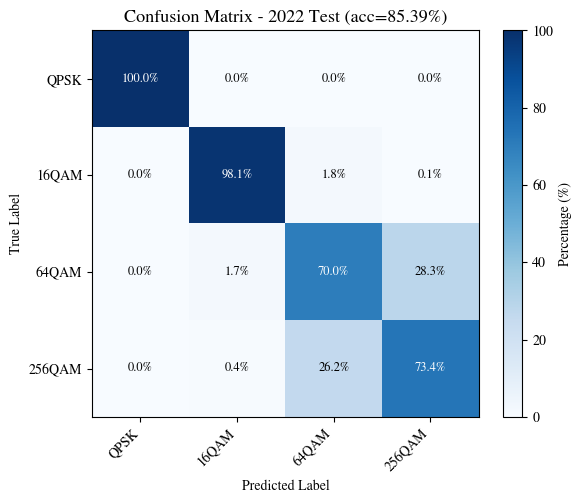

2018 TEST (external): loss=0.4050 acc=80.27%


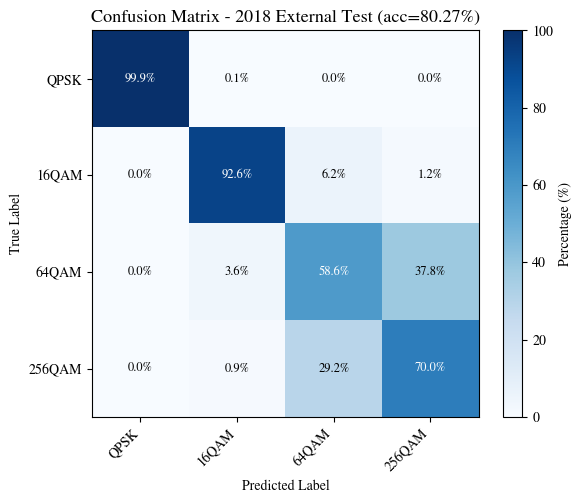


2022 TEST     : 85.3875%
2018 TEST (ext): 80.2709%


In [9]:
@torch.no_grad()
def plot_confusion(cm, title, class_names):
    cm = cm.astype(np.float64)
    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    cm_percent = cm / row_sums * 100.0

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm_percent, interpolation="nearest", cmap="Blues", vmin=0, vmax=100)
    ax.set_title(title, fontsize=13)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Percentage (%)")
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            value = cm_percent[i, j]
            ax.text(j, i, f"{value:.1f}%", ha="center", va="center", color="white" if value > 50 else "black", fontsize=9)
    ax.set_ylabel("True Label")
    ax.set_xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()

BEST_MODEL_PATH = BASE_DIR / "fully_online_pipeline_models" / f"capnet_lite_c{C1}_{C2}_{SPLIT_MODE}.pt"
state = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(state)
model.eval()

print("Loaded CAPNetLite weights from:", BEST_MODEL_PATH)

te_loss, te_acc, y_true, y_pred = eval_one(test_loader)
cm = confusion_matrix(y_true, y_pred, labels=list(range(N_CLASSES)))
print(f"{TRAIN_SET_NAME} TEST: loss={te_loss:.4f} acc={te_acc*100:.2f}%")
plot_confusion(cm, f"Confusion Matrix - {TRAIN_SET_NAME} Test (acc={te_acc*100:.2f}%)", CLASS_NAMES)

ex_loss, ex_acc, y_true_ex, y_pred_ex = eval_one(ext_loader)
cm_ex = confusion_matrix(y_true_ex, y_pred_ex, labels=list(range(N_CLASSES)))
print(f"{EXT_SET_NAME} TEST (external): loss={ex_loss:.4f} acc={ex_acc*100:.2f}%")
plot_confusion(cm_ex, f"Confusion Matrix - {EXT_SET_NAME} External Test (acc={ex_acc*100:.2f}%)", CLASS_NAMES)

print()
print("=" * 60)

print(f"{TRAIN_SET_NAME} TEST     : {te_acc*100:.4f}%")
print(f"{EXT_SET_NAME} TEST (ext): {ex_acc*100:.4f}%")
print("=" * 60)


## Full Pipeline Simulation

This final stage combines LR55 routing and the trained CAPNetLite. It evaluates the simulated full 8-class pipeline without regenerating CC matrices for non-QPSK-like signals.


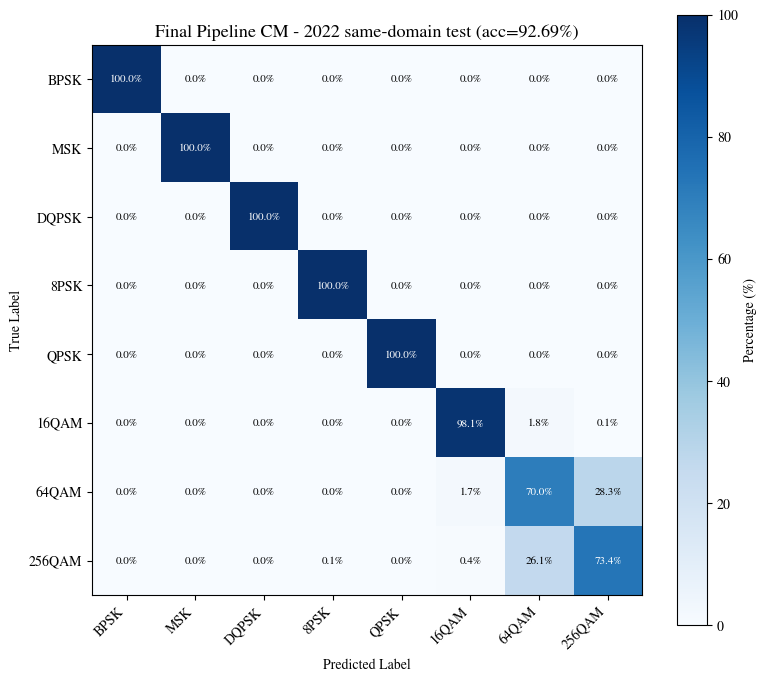

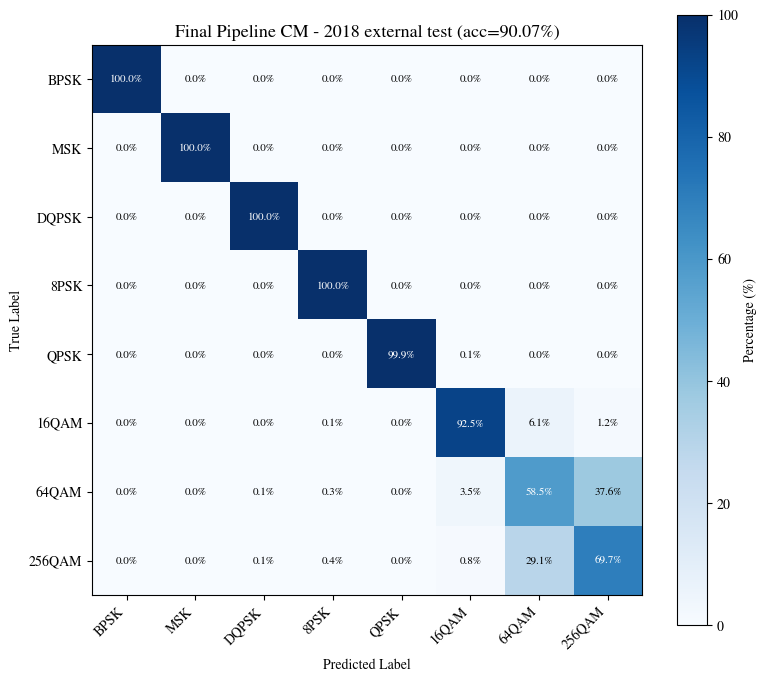

In [10]:
# =========================
# Stage 3: full 8-class pipeline simulation
# =========================
@torch.no_grad()
def predict_capnetlite_batches(X_tensor, batch_size=BATCH_SIZE):
    if X_tensor.numel() == 0:
        return np.asarray([], dtype=np.int64)
    loader = DataLoader(torch.utils.data.TensorDataset(X_tensor), batch_size=batch_size, shuffle=False)
    preds = []
    model.eval()
    for (X_batch,) in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        logits = model(X_batch)
        preds.append(logits.argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


def load_qpsklike_cc_lookup(files_by_year):
    # Load precomputed QPSK-like CC matrices and map them by (year, batch_id, signal_index).
    cc_lookup = {}
    for year, files in files_by_year.items():
        for path in files:
            pack = torch.load(path, map_location="cpu", weights_only=False)
            X_all = pack["estimate_abs"].float()
            if X_all.ndim != 3 or tuple(X_all.shape[1:]) != (11, 24):
                raise ValueError(f"{path.name}: expected estimate_abs [N,11,24], got {tuple(X_all.shape)}")

            status = pack.get("status", torch.ones(X_all.shape[0], dtype=torch.bool)).bool()
            signal_type = [str(s).strip().lower() for s in list(pack["signal_type"])]
            label_ok = torch.tensor([s in LABEL_MAP for s in signal_type], dtype=torch.bool)
            power_all = pack["boi_inband_signal"].float()
            power_ok = torch.isfinite(power_all) & (power_all > 0)
            snr_ok = torch.ones(X_all.shape[0], dtype=torch.bool)
            if DROP_2018_NEGATIVE_SNR and path.name.startswith("2018_") and "snr" in pack:
                snr_all = pack["snr"].float()
                snr_ok = torch.isfinite(snr_all) & (snr_all >= 0)
            X_11x15_all = X_all[:, :, :15]
            X_ok = torch.isfinite(X_11x15_all.reshape(X_11x15_all.shape[0], -1)).all(dim=1)
            valid = status & label_ok & power_ok & snr_ok & X_ok
            valid_idx = torch.where(valid)[0]

            X = X_11x15_all[valid] / power_all[valid].view(-1, 1, 1)
            scaled_ok = torch.isfinite(X.reshape(X.shape[0], -1)).all(dim=1)
            X = X[scaled_ok]
            valid_idx = valid_idx[scaled_ok]

            signal_indices = pack["signal_index"].long()
            batch_id = int(pack.get("meta", {}).get("batch_id", -1))
            if batch_id < 0:
                batch_id = int(path.stem.split("batch_")[-1].split(".")[0].split("_")[0])

            for out_i, src_i in enumerate(valid_idx.tolist()):
                key = (str(year), batch_id, int(signal_indices[src_i]))
                cc_lookup[key] = {
                    "X": X[out_i].unsqueeze(0),
                    "signal_type": signal_type[src_i],
                    "label8": label8_from_signal_type(signal_type[src_i]),
                    "source_pt": path.name,
                }
    return cc_lookup


cc_lookup = load_qpsklike_cc_lookup(pt_files)


def plot_final_confusion(cm_counts, title, class_names):
    cm_counts = np.asarray(cm_counts, dtype=np.float64)
    row_sums = cm_counts.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    cm_percent = cm_counts / row_sums * 100.0

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm_percent, interpolation="nearest", cmap="Blues", vmin=0, vmax=100)
    ax.set_title(title, fontsize=13)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Percentage (%)")

    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)

    thresh = 50.0
    for i in range(cm_percent.shape[0]):
        for j in range(cm_percent.shape[1]):
            value = cm_percent[i, j]
            ax.text(
                j,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="white" if value > thresh else "black",
                fontsize=8,
            )

    ax.set_ylabel("True Label")
    ax.set_xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()


def evaluate_full_pipeline(mask, name, make_plot=True):
    rows = lr_meta_df.loc[mask].copy().reset_index(drop=True)
    X_lr = X_lr55[mask]
    true5 = rows["label5"].astype(str).to_numpy()
    true8 = rows["label8"].astype(str).to_numpy()
    pred5 = lr55_model.predict(X_lr)

    final_pred = np.empty(len(rows), dtype=object)
    route = np.empty(len(rows), dtype=object)
    nn_positions = []
    nn_tensors = []
    missing_cc = []

    for i, (row, coarse_pred) in enumerate(zip(rows.itertuples(index=False), pred5)):
        if coarse_pred != "QPSK-like":
            # LR routes this signal away from QPSK-like, so the NN stage is not used.
            final_pred[i] = coarse_pred
            route[i] = "lr_non_qpsklike"
            continue

        if row.label5 != "QPSK-like":
            # False QPSK-like from LR has no precomputed CC matrix; simulate it as QPSK.
            final_pred[i] = "QPSK"
            route[i] = "lr_false_qpsklike_forced_qpsk"
            continue

        item = cc_lookup.get(row.cc_key)
        if item is None:
            # Unexpected after the 2018 negative-SNR filter; keep a deterministic fallback.
            final_pred[i] = "QPSK"
            route[i] = "true_qpsklike_missing_cc_forced_qpsk"
            missing_cc.append(row.cc_key)
            continue

        nn_positions.append(i)
        nn_tensors.append(item["X"])
        route[i] = "lr_qpsklike_capnetlite"

    if nn_tensors:
        X_nn = torch.cat(nn_tensors, dim=0).unsqueeze(1)
        pred4 = predict_capnetlite_batches(X_nn)
        for pos, pred_idx in zip(nn_positions, pred4):
            final_pred[pos] = CLASS_NAMES[int(pred_idx)]

    lr5_acc = accuracy_score(true5, pred5)
    full8_acc = accuracy_score(true8, final_pred)
    cm8 = pd.DataFrame(
        confusion_matrix(true8, final_pred, labels=FULL8_LABEL_ORDER),
        index=FULL8_LABEL_ORDER,
        columns=FULL8_LABEL_ORDER,
    )
    route_counts = pd.Series(route).value_counts().rename_axis("route").to_frame("count")
    true_qpsklike = true5 == "QPSK-like"
    lr_qpsklike = pred5 == "QPSK-like"
    summary = {
        "name": name,
        "n": int(len(rows)),
        "lr5_acc_percent": float(lr5_acc * 100),
        "full8_acc_percent": float(full8_acc * 100),
        "full8_errors": int((final_pred != true8).sum()),
        "nn_used": int(len(nn_positions)),
        "true_qpsklike_lr_non_qpsklike": int((true_qpsklike & ~lr_qpsklike).sum()),
        "non_qpsklike_lr_qpsklike_forced_qpsk": int((~true_qpsklike & lr_qpsklike).sum()),
        "missing_cc_forced_qpsk": int(len(missing_cc)),
    }

    if make_plot:
        plot_final_confusion(
            cm8.to_numpy(),
            f"Final Pipeline CM - {name} (acc={full8_acc*100:.2f}%)",
            FULL8_LABEL_ORDER,
        )

    return summary, cm8, route_counts, rows.assign(pred5=pred5, pred8=final_pred, route=route)


pipeline_results = {}
for name, mask in [
    (f"{TRAIN_SET_NAME} same-domain test", lr_test_mask),
    (f"{EXT_SET_NAME} external test", lr_ext_mask),
]:
    pipeline_results[name] = evaluate_full_pipeline(mask, name, make_plot=True)

summary_df = pd.DataFrame([v[0] for v in pipeline_results.values()])


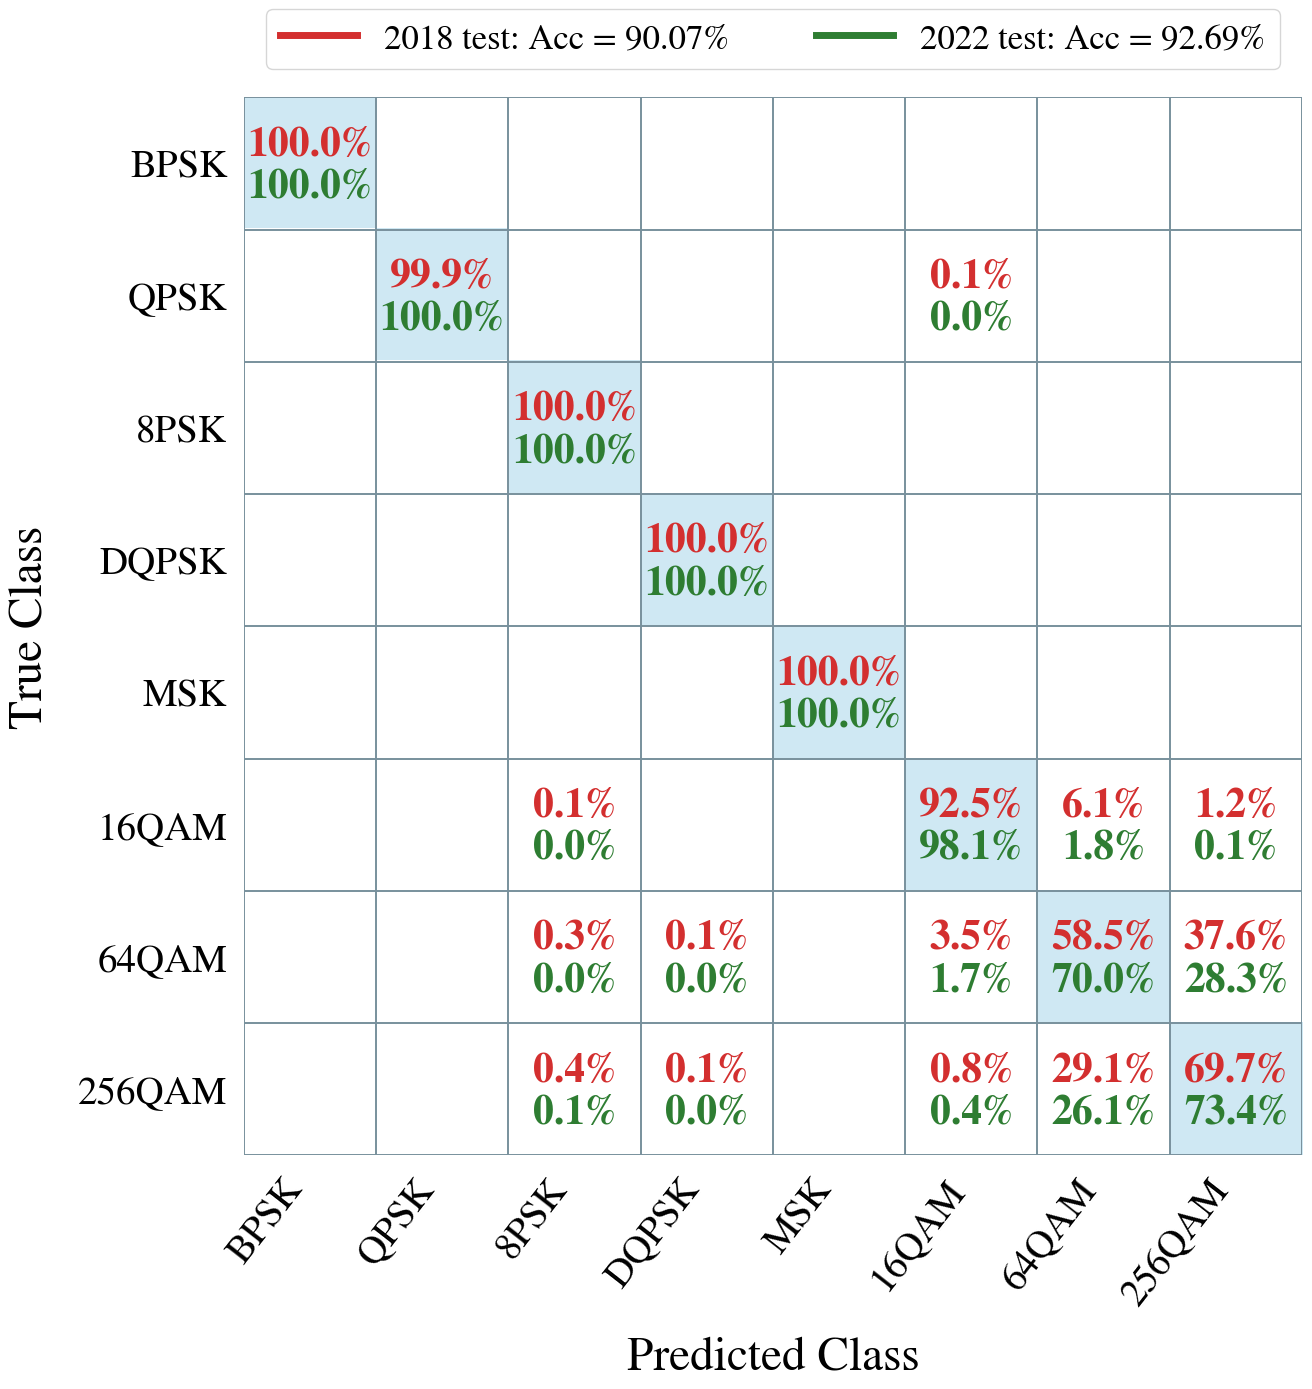

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})
def row_normalize_cm(cm):
    cm = np.asarray(cm, dtype=np.float64)
    row_sum = cm.sum(axis=1, keepdims=True)
    row_sum[row_sum == 0] = 1.0
    return cm / row_sum * 100.0


def plot_combined_confusion(
    cm_2018,
    cm_2022,
    acc_2018,
    acc_2022,
    class_names,
    save_path=None,
):
    cm_2018_pct = row_normalize_cm(cm_2018)
    cm_2022_pct = row_normalize_cm(cm_2022)

    n_classes = len(class_names)

    # Light blue off-diagonal cells and gold diagonal cells.
    background = np.eye(n_classes)
    cmap = ListedColormap([
            "#FFFFFF",  # off-diagonal
            "#CFE8F3",  # diagonal
        ])

    fig, ax = plt.subplots(figsize=(16, 14))
    ax.imshow(
        background,
        cmap=cmap,
        vmin=0,
        vmax=1,
        interpolation="nearest",
        aspect="equal",
    )

    # Cell borders.
    ax.set_xticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.grid(
        which="minor",
        color="#78909C",
        linestyle="-",
        linewidth=1.4,
    )
    ax.tick_params(which="minor", bottom=False, left=False)

    # Axis ticks and labels.
    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))

    ax.set_xticklabels(
        class_names,
        rotation=52,
        ha="right",
        fontsize=28,
    )
    ax.set_yticklabels(
        class_names,
        fontsize=28,
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=34,
        labelpad=18,
    )
    ax.set_ylabel(
        "True Class",
        fontsize=34,
        labelpad=18,
    )

    # Two percentages in each cell.
    # Two percentages in each cell.
    # If both displayed values are 0.0%, leave the cell blank.
    for i in range(n_classes):
        for j in range(n_classes):
            value_2018 = cm_2018_pct[i, j]
            value_2022 = cm_2022_pct[i, j]

            # 按一位小数显示时，两者均为 0.0% 就留白。
            if round(value_2018, 1) == 0.0 and round(value_2022, 1) == 0.0:
                continue

            ax.text(
                j,
                i - 0.14,
                f"{value_2018:.1f}%",
                ha="center",
                va="center",
                color="#D32F2F",
                fontsize=30,
                fontweight="bold",
            )

            ax.text(
                j,
                i + 0.18,
                f"{value_2022:.1f}%",
                ha="center",
                va="center",
                color="#2E7D32",
                fontsize=30,
                fontweight="bold",
            )

    # Legend containing total accuracy.
    legend_handles = [
        Line2D(
            [0], [0],
            color="#D32F2F",
            linewidth=5,
            label=f"2018 test: Acc = {acc_2018:.2f}%",
        ),
        Line2D(
            [0], [0],
            color="#2E7D32",
            linewidth=5,
            label=f"2022 test: Acc = {acc_2022:.2f}%",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.01),
        ncol=2,
        frameon=True,
        fontsize=25,
        handlelength=2.2,
        columnspacing=2.5,
    )

    # No title and no colorbar.
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(axis="both", which="major", length=0, pad=12)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()


# ============================================================
# Evaluate without drawing the original two separate matrices
# ============================================================
pipeline_results = {}

for name, mask in [
    (f"{TRAIN_SET_NAME} same-domain test", lr_test_mask),
    (f"{EXT_SET_NAME} external test", lr_ext_mask),
]:
    pipeline_results[name] = evaluate_full_pipeline(
        mask,
        name,
        make_plot=False,
    )

summary_df = pd.DataFrame(
    [result[0] for result in pipeline_results.values()]
)


# ============================================================
# Extract 2018 and 2022 confusion matrices
# ============================================================
result_by_year = {}

for _, result in pipeline_results.items():
    summary, cm, route_counts, details = result

    # Determine the evaluation year from the sample metadata.
    test_years = details["year"].astype(str).unique()
    if len(test_years) != 1:
        raise ValueError(
            f"Expected one test year, found {test_years}"
        )

    test_year = test_years[0]
    result_by_year[test_year] = {
        "summary": summary,
        "cm": cm,
    }

if "2018" not in result_by_year or "2022" not in result_by_year:
    raise KeyError(
        "Both 2018 and 2022 results are required to draw the combined CM."
    )


# Order matching the example figure.
PLOT_CLASS_ORDER = [
    "BPSK",
    "QPSK",
    "8PSK",
    "DQPSK",
    "MSK",
    "16QAM",
    "64QAM",
    "256QAM",
]

cm_2018 = result_by_year["2018"]["cm"].reindex(
    index=PLOT_CLASS_ORDER,
    columns=PLOT_CLASS_ORDER,
    fill_value=0,
)

cm_2022 = result_by_year["2022"]["cm"].reindex(
    index=PLOT_CLASS_ORDER,
    columns=PLOT_CLASS_ORDER,
    fill_value=0,
)

acc_2018 = result_by_year["2018"]["summary"]["full8_acc_percent"]
acc_2022 = result_by_year["2022"]["summary"]["full8_acc_percent"]


plot_combined_confusion(
    cm_2018=cm_2018.to_numpy(),
    cm_2022=cm_2022.to_numpy(),
    acc_2018=acc_2018,
    acc_2022=acc_2022,
    class_names=PLOT_CLASS_ORDER,

    
    save_path=None,
    
)

In [12]:
# Save per-sample results for SNR-accuracy plotting.
# Run this after pipeline_results has been generated.

save_data = {
    "split_mode": SPLIT_MODE,
    "results": {},
}

for result_name, result in pipeline_results.items():
    summary, cm, route_counts, details = result

    required_columns = {"year", "snr", "label8", "pred8"}
    missing = required_columns - set(details.columns)
    if missing:
        raise KeyError(f"Missing columns: {missing}")

    test_years = details["year"].astype(str).unique()
    if len(test_years) != 1:
        raise ValueError(f"Expected one test year, found {test_years}")

    test_year = test_years[0]

    save_data["results"][test_year] = {
        "result_name": result_name,
        "test_year": test_year,
        "snr": torch.tensor(
            details["snr"].to_numpy(dtype=np.float32)
        ),
        "true_type": details["label8"].astype(str).tolist(),
        "pred_type": details["pred8"].astype(str).tolist(),
        "overall_accuracy": summary["full8_acc_percent"] / 100.0,
    }

save_path = f"snr_acc_samples_{SPLIT_MODE}.pt"
torch.save(save_data, save_path)

print("Saved:", save_path)
for year, data in save_data["results"].items():
    print(
        year,
        "samples =", len(data["true_type"]),
        "accuracy =", f'{data["overall_accuracy"] * 100:.2f}%'
    )

Saved: snr_acc_samples_2022train20.pt
2022 samples = 16000 accuracy = 92.69%
2018 samples = 111632 accuracy = 90.07%
